K-Means Clustering Assignment

Step 1: Reading the Dataset
--------------------------------------------------
Dataset:
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   

         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   

                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  

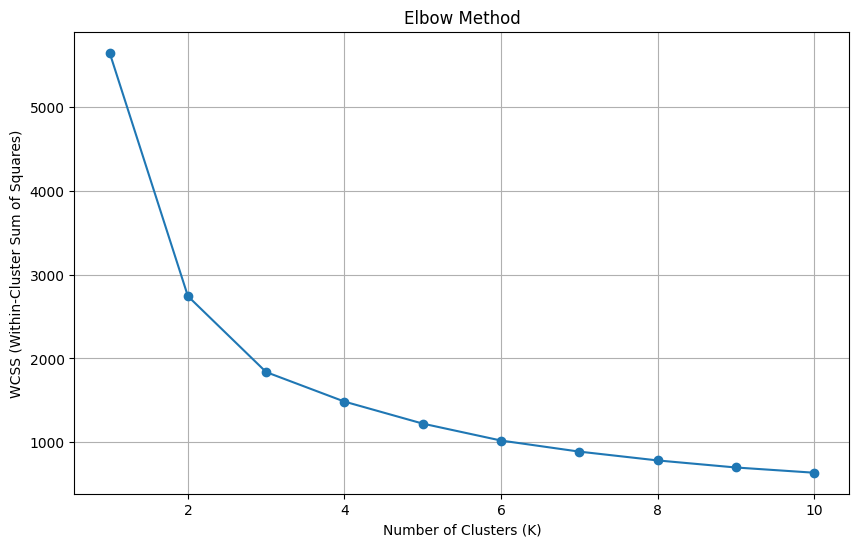

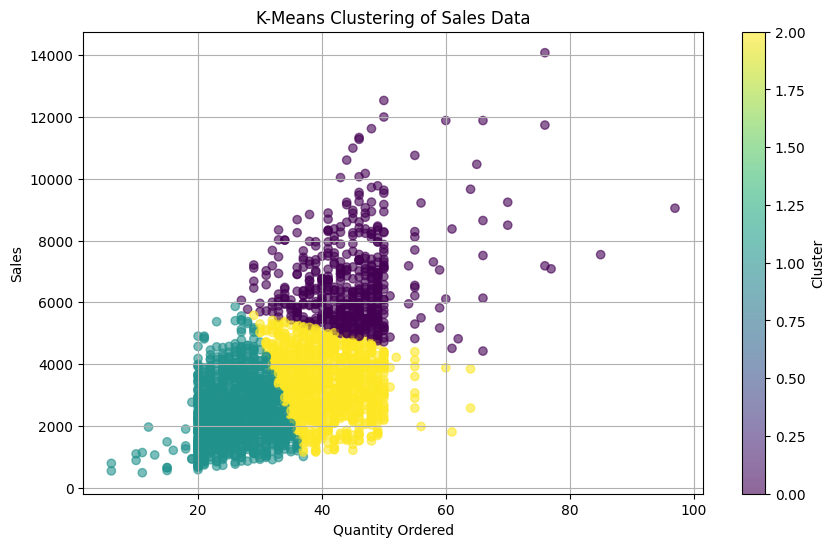

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

print("K-Means Clustering Assignment")
print("=" * 50)

# 1. Read the dataset
print("\nStep 1: Reading the Dataset")
print("-" * 50)
data = pd.read_csv("sales_data_sample.csv", encoding="unicode_escape")

print("Dataset:")
print(data.head())

# 2. Select numerical features
print("\nStep 2: Selecting Numerical Features")
print("-" * 50)
X = data[["QUANTITYORDERED", "SALES"]].dropna()
print(f"Selected features shape: {X.shape}")

# 3. Normalize the data
print("\nStep 3: Normalizing the Data")
print("-" * 50)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Data normalized using StandardScaler")

# 4. Find the optimal number of clusters using elbow method
print("\nStep 4: Finding Optimal K using Elbow Method")
print("-" * 50)
wcss = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    wcss.append(model.inertia_)

print("WCSS values for K=1 to K=10:")
for k, wcss_value in enumerate(wcss, 1):
    print(f"K={k}: WCSS={wcss_value:.2f}")

# Plot elbow graph
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS (Within-Cluster Sum of Squares)")
plt.grid(True)
plt.savefig('elbow_method.png')
print("\nElbow method plot saved as 'elbow_method.png'")

# 5. Apply K-Means using selected K
print("\nStep 5: Applying K-Means Clustering")
print("-" * 50)
k = 3  # Choose K after inspecting the elbow graph
print(f"Using K={k} for clustering")

kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# 6. Display cluster assignments
print("\nStep 6: Cluster Assignments")
print("-" * 50)
result = data.loc[X.index].copy()
result["Cluster"] = clusters

print("\nFirst 10 records with cluster assignments:")
print(result[["QUANTITYORDERED", "SALES", "Cluster"]].head(10))

print("\nNumber of records in each cluster:")
print(result["Cluster"].value_counts().sort_index())

# 7. Visualize the clusters
print("\nStep 7: Visualizing Clusters")
print("-" * 50)
plt.figure(figsize=(10, 6))
plt.scatter(
    X["QUANTITYORDERED"],
    X["SALES"],
    c=clusters,
    cmap="viridis",
    alpha=0.6
)
plt.title("K-Means Clustering of Sales Data")
plt.xlabel("Quantity Ordered")
plt.ylabel("Sales")
plt.colorbar(label='Cluster')
plt.grid(True)
plt.savefig('clusters_visualization.png')
print("\nCluster visualization saved as 'clusters_visualization.png'")

print("\n" + "=" * 50)
print("Assignment Completed Successfully!")
print("=" * 50)
